
# Simulated Annealing untuk Optimasi Portofolio Saham LQ45

Notebook ini berisi eksperimen optimasi portofolio saham LQ45 menggunakan
algoritma Simulated Annealing (SA).

Implementasi algoritma menggunakan modul `src/algorithms/sa.py`, sedangkan
data dan konfigurasi masalah menggunakan modul yang telah tersedia dalam
repository.

Eksperimen dilakukan untuk mencari kombinasi saham dan alokasi dana yang
memaksimalkan return ekspektasi dengan mempertimbangkan batas risiko,
batas jumlah saham, dan keterbatasan modal.

Tahapan eksperimen:
1. Setup dan parameter.
2. Pemuatan data dan pembentukan masalah optimasi.
3. Pengujian satu run SA.
4. Analisis saham terpilih dan alokasi modal.
5. Visualisasi konvergensi.
6. Eksperimen multi-seed dan ringkasan hasil.

In [4]:

from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cari root repository secara otomatis
ROOT = Path.cwd().resolve()

if not (ROOT / "src").is_dir():
    if (ROOT.parent / "src").is_dir():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError(
            "Folder src tidak ditemukan. "
            "Buka notebook dari dalam repository proyek."
        )

SRC = ROOT / "src"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data import muat_jendela, buat_problem
from algorithms import sa

# Parameter eksperimen awal
NAMA_DATA = "kasus_tetap"
K = 7
SIGMA_MULT = 1.5
SEED = 0
BUDGET_UJI = 100

np.set_printoptions(precision=4, suppress=True)

print("Root repository :", ROOT)
print("Data            :", NAMA_DATA)
print("K               :", K)
print("Pengali risiko  :", SIGMA_MULT)
print("Seed            :", SEED)
print("Budget uji      :", BUDGET_UJI)
print("SA berhasil diimpor:", hasattr(sa, "run"))


Root repository : C:\Users\Lailatul Fitaliqoh\IdeaProjects\SC\OptimasiPortofolioSaham
Data            : kasus_tetap
K               : 7
Pengali risiko  : 1.5
Seed            : 0
Budget uji      : 100
SA berhasil diimpor: True


In [5]:

# Memuat data dan membentuk problem optimasi
data = muat_jendela(NAMA_DATA)

P = buat_problem(
    data,
    K=K,
    mult=SIGMA_MULT,
    label=NAMA_DATA
)

print("Label masalah:", P.label)
print("Jumlah kandidat saham:", P.n)
print("Panjang kromosom:", P.n_genes)
print("Modal: Rp {:,.0f}".format(P.D))
print("Batas jumlah saham:", P.K)
print("Batas risiko:", round(P.sigma_max, 6))
print("Batas bobot saham:", P.cap)
print("Jumlah saham layak dibeli:", int(P.layak_beli.sum()))


Label masalah: kasus_tetap
Jumlah kandidat saham: 42
Panjang kromosom: 85
Modal: Rp 5,000,000
Batas jumlah saham: 7
Batas risiko: 0.238969
Batas bobot saham: 0.2
Jumlah saham layak dibeli: 39


In [6]:

# Uji coba satu run Simulated Annealing
hasil_sa = sa.run(
    P,
    budget=BUDGET_UJI,
    seed=SEED
)

print("Status:", hasil_sa.status)
print("Jumlah evaluasi:", hasil_sa.n_eval)
print("Return:", hasil_sa.R)
print("Risiko:", hasil_sa.sigma)
print("Pelanggaran:", hasil_sa.viol)
print("Layak:", hasil_sa.feasible)
print("Waktu eksekusi:", round(hasil_sa.seconds, 4), "detik")


Status: 
Jumlah evaluasi: 100
Return: 0.3005117831118742
Risiko: 0.22174270744845717
Pelanggaran: 0.0
Layak: True
Waktu eksekusi: 0.0483 detik


In [7]:

# Memeriksa solusi portofolio hasil SA
print("Tipe hasil:", type(hasil_sa))
print("Atribut hasil:", hasil_sa.__dict__.keys())
print("Lots:", hasil_sa.lots)
print("Bobot/kromosom:", hasil_sa.x)


Tipe hasil: <class 'problem.Result'>
Atribut hasil: dict_keys(['lots', 'R', 'sigma', 'viol', 'feasible', 'history', 'n_eval', 'seconds', 'seed', 'x', 'n_eval_best', 'status', 'trace'])
Lots: [0 3 8 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0 0
 0 0 0 0 0]
Bobot/kromosom: [0.0649 0.9073 0.8478 0.7362 0.4735 0.0255 0.6761 0.7906 0.7267 0.5125
 0.3824 0.719  0.6937 1.     0.0454 0.3002 0.763  0.4935 0.2097 0.372
 0.4587 0.5474 0.5205 0.4099 0.2575 0.5265 0.9471 0.6179 0.3238 0.6793
 0.3918 1.     0.2904 0.8105 0.8739 0.2497 0.0582 0.1885 0.4727 0.1621
 0.7377 0.1098 0.4581 0.443  0.8256 0.7103 0.5216 0.8668 0.6923 0.4512
 0.589  0.8727 0.7386 0.9714 0.5586 0.6643 0.7157 0.8938 0.4018 0.5846
 0.937  0.3301 0.8759 0.5908 0.8809 0.307  0.5555 0.355  0.7568 0.4917
 0.7919 0.9607 0.3888 1.     0.3416 0.4211 0.5115 0.6422 0.9835 0.843
 0.5162 0.4889 0.9042 0.9169 0.    ]


In [8]:

# Menampilkan saham yang dipilih SA berdasarkan jumlah lot
portofolio_sa = pd.DataFrame({
    "Saham": P.tickers,
    "Harga per Lembar": P.price,
    "Lot Terpilih": hasil_sa.lots,
})

portofolio_sa["Jumlah Lembar"] = (
    portofolio_sa["Lot Terpilih"] * P.lot
)
portofolio_sa["Nilai Investasi"] = (
    portofolio_sa["Jumlah Lembar"] * portofolio_sa["Harga per Lembar"]
)

portofolio_sa = portofolio_sa[
    portofolio_sa["Lot Terpilih"] > 0
].copy()

display(portofolio_sa)
print(
    "Total investasi: Rp {:,.0f}".format(
        portofolio_sa["Nilai Investasi"].sum()
    )
)


,Saham,Harga per Lembar,Lot Terpilih,Jumlah Lembar,Nilai Investasi
1,ADRO,1690.0,3,300,507000.0
2,AKRA,1210.0,8,800,968000.0
13,BRPT,3750.0,2,200,750000.0
31,MEDC,1370.0,7,700,959000.0
33,PGAS,1690.0,3,300,507000.0
34,PTBA,2350.0,2,200,470000.0


Total investasi: Rp 4,161,000


In [9]:

# Memeriksa komponen kas dan kelayakan solusi
from decoder import decode_batch

decoded_sa = decode_batch(hasil_sa.x.reshape(1, -1), P)

print("Hasil decode:")
print(decoded_sa)

print("\nRingkasan solusi:")
print("Modal awal       : Rp {:,.0f}".format(P.D))
print("Total investasi  : Rp {:,.0f}".format(
    portofolio_sa["Nilai Investasi"].sum()
))
print("Sisa modal       : Rp {:,.0f}".format(
    P.D - portofolio_sa["Nilai Investasi"].sum()
))
print("Return           :", hasil_sa.R)
print("Risiko           :", hasil_sa.sigma)
print("Feasible         :", hasil_sa.feasible)


Hasil decode:
(array([[0, 3, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 3, 2, 0, 0, 0, 0, 0, 0, 0]]), array([[0.    , 0.1014, 0.1936, 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    , 0.15  , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.1918,
        0.    , 0.1014, 0.094 , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    ]]), array([0.1678]))

Ringkasan solusi:
Modal awal       : Rp 5,000,000
Total investasi  : Rp 4,161,000
Sisa modal       : Rp 839,000
Return           : 0.3005117831118742
Risiko           : 0.22174270744845717
Feasible         : True


In [10]:

# Memeriksa riwayat konvergensi SA
print("Tipe history:", type(hasil_sa.history))
print("Isi history:")
print(hasil_sa.history)


Tipe history: <class 'list'>
Isi history:
[]


In [11]:

# Jalankan SA kembali sambil merekam prosesnya
hasil_sa = sa.run(
    P,
    budget=BUDGET_UJI,
    seed=SEED,
    trace=True
)

print("Jumlah evaluasi:", hasil_sa.n_eval)
print("History:", hasil_sa.history)
print("Trace tersedia:", hasil_sa.trace is not None)


Jumlah evaluasi: 100
History: []
Trace tersedia: True


In [12]:

# Periksa struktur trace SA
print("Tipe trace:", type(hasil_sa.trace))

if isinstance(hasil_sa.trace, dict):
    print("Kolom trace:", hasil_sa.trace.keys())
    for nama, isi in hasil_sa.trace.items():
        print(f"\n{nama}:")
        print(isi[:5] if hasattr(isi, "__getitem__") else isi)
else:
    print(hasil_sa.trace)


Tipe trace: <class 'dict'>
Kolom trace: dict_keys(['R', 'sigma', 'viol', 'g0', 'kas', 'n_unik', 'lots_terbaik', 'temperature'])

R:
[[0.2898]
 [0.2898]
 [0.2898]
 [0.2898]
 [0.2898]]

sigma:
[[0.2171]
 [0.2171]
 [0.2171]
 [0.2171]
 [0.2171]]

viol:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]]

g0:
[[0.0511]
 [0.0511]
 [0.0511]
 [0.0511]
 [0.0511]]

kas:
[[0.172]
 [0.172]
 [0.172]
 [0.172]
 [0.172]]

n_unik:
[1 1 1 1 1]

lots_terbaik:
[[0 2 4 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0
  0 0 0 0 0 0]
 [0 2 4 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0
  0 0 0 0 0 0]
 [0 2 4 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0
  0 0 0 0 0 0]
 [0 2 4 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0
  0 0 0 0 0 0]
 [0 2 4 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 0 3 2 0
  0 0 0 0 0 0]]

temperature:
[1.     0.9326 0.8697 0.8111 0.7565]


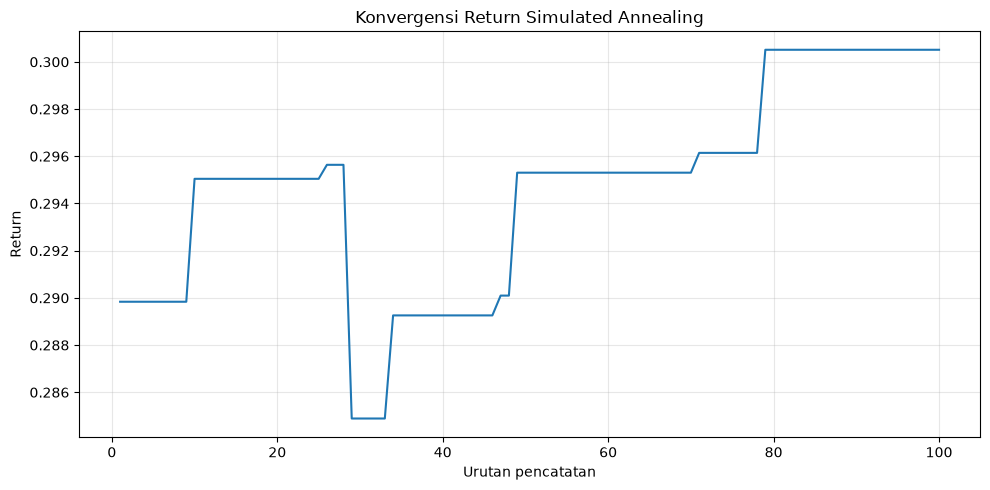

In [13]:

# Visualisasi konvergensi return SA
trace_sa = hasil_sa.trace

return_trace = np.asarray(trace_sa["R"]).reshape(-1)
evaluasi = np.arange(1, len(return_trace) + 1)

plt.figure(figsize=(10, 5))
plt.plot(evaluasi, return_trace)
plt.xlabel("Urutan pencatatan")
plt.ylabel("Return")
plt.title("Konvergensi Return Simulated Annealing")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


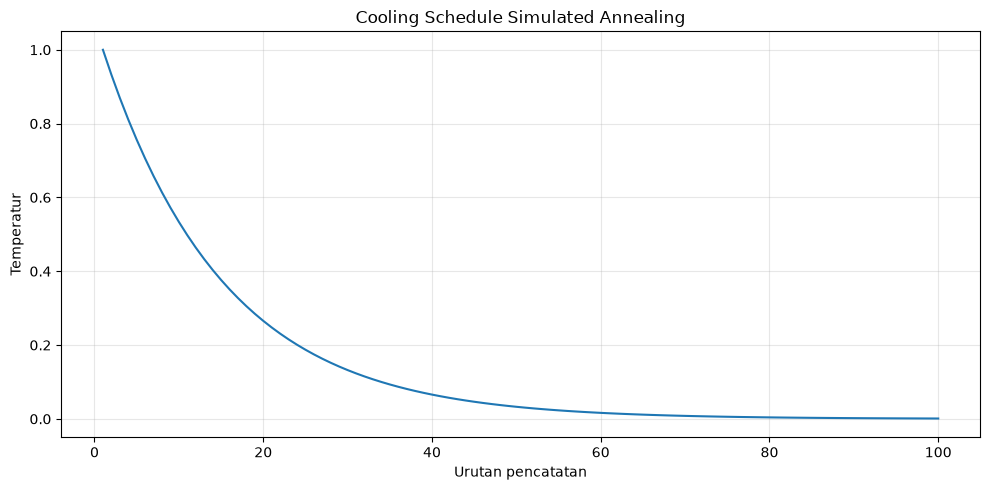

In [14]:

# Visualisasi cooling schedule Simulated Annealing
temperature = np.asarray(
    hasil_sa.trace["temperature"]
).reshape(-1)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(temperature) + 1), temperature)
plt.xlabel("Urutan pencatatan")
plt.ylabel("Temperatur")
plt.title("Cooling Schedule Simulated Annealing")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

# Uji SA setelah penambahan kalibrasi
hasil_uji_kalibrasi = sa.run(
    P,
    budget=100,
    seed=0,
    trace=True
)

print("Jumlah evaluasi:", hasil_uji_kalibrasi.n_eval)
print("Return:", hasil_uji_kalibrasi.R)
print("Risiko:", hasil_uji_kalibrasi.sigma)
print("Pelanggaran:", hasil_uji_kalibrasi.viol)
print("Layak:", hasil_uji_kalibrasi.feasible)
print("Trace tersedia:", hasil_uji_kalibrasi.trace is not None)


Jumlah evaluasi: 100
Return: 0.3005117831118742
Risiko: 0.22174270744845717
Pelanggaran: 0.0
Layak: True
Trace tersedia: True


In [16]:

# Periksa apakah trace mencatat temperatur hasil kalibrasi
trace_uji = hasil_uji_kalibrasi.trace

print("Jumlah evaluasi:", hasil_uji_kalibrasi.n_eval)
print("Temperatur awal pada trace:", trace_uji["temperature"][0])
print("Temperatur akhir pada trace:", trace_uji["temperature"][-1])
print("Jumlah titik trace:", len(trace_uji["temperature"]))
print("Target rasio temperatur akhir:", sa.SA_PARAM["T_end_ratio"])


Jumlah evaluasi: 100
Temperatur awal pada trace: 1.0
Temperatur akhir pada trace: 0.0010000000000000028
Jumlah titik trace: 100
Target rasio temperatur akhir: 0.001


In [18]:

import importlib
importlib.reload(sa)

print("Fungsi kalibrasi tersedia:", hasattr(sa, "calibrate_temperature"))


Fungsi kalibrasi tersedia: True


In [19]:

# Ulangi pemeriksaan temperatur hasil kalibrasi
rng_cek = np.random.default_rng(SEED)
ev_cek = sa.Evaluator(P, budget=100)

x_cek = sa.init_population(P, rng_cek, 1, n_seed=1)[0]
R_cek, sigma_cek, viol_cek = ev_cek.evaluate(x_cek)

T_R_cek = max(abs(float(R_cek[0])) * 0.05, 1e-4)
T_v_cek = max(P.sigma_max * 0.05, 1e-5)

T0_cek = sa.calibrate_temperature(
    x_cek,
    float(R_cek[0]),
    float(viol_cek[0]),
    P,
    ev_cek,
    rng_cek,
    n_samples=30,
    target_acceptance=0.80,
    p_swap=sa.SA_PARAM["p_swap"],
    p_cash=sa.SA_PARAM["p_cash"],
    sigma_mut=sa.SA_PARAM["sigma_mut"],
    T_R=T_R_cek,
    T_v=T_v_cek,
)

print("Temperatur hasil kalibrasi:", T0_cek)
print("Evaluasi yang digunakan:", ev_cek.n_eval)


Temperatur hasil kalibrasi: 13.652264916279677
Evaluasi yang digunakan: 31


In [20]:

# Jalankan SA dengan kalibrasi dan periksa anggarannya
hasil_uji_final = sa.run(
    P,
    budget=100,
    seed=0,
    trace=True
)

print("Total evaluasi:", hasil_uji_final.n_eval)
print("Temperatur awal:", hasil_uji_final.trace["temperature"][0])
print("Temperatur akhir:", hasil_uji_final.trace["temperature"][-1])
print("Jumlah titik trace:", len(hasil_uji_final.trace["temperature"]))
print("Feasible:", hasil_uji_final.feasible)


Total evaluasi: 100
Temperatur awal: 13.652264916279677
Temperatur akhir: 0.013652264916279713
Jumlah titik trace: 70
Feasible: True


In [21]:
import importlib
importlib.reload(sa)

<module 'algorithms.sa' from 'C:\\Users\\Lailatul Fitaliqoh\\IdeaProjects\\SC\\OptimasiPortofolioSaham\\src\\algorithms\\sa.py'>

In [22]:

hasil_uji_final = sa.run(
    P,
    budget=100,
    seed=0,
    trace=True
)

print("Total evaluasi:", hasil_uji_final.n_eval)
print("Temperatur awal:", hasil_uji_final.trace["temperature"][0])
print("Temperatur akhir:", hasil_uji_final.trace["temperature"][-1])
print("Target temperatur akhir:", hasil_uji_final.trace["temperature"][0] * 0.001)
print("Jumlah titik trace:", len(hasil_uji_final.trace["temperature"]))
print("Feasible:", hasil_uji_final.feasible)


Total evaluasi: 100
Temperatur awal: 13.652264916279677
Temperatur akhir: 0.013652264916279713
Target temperatur akhir: 0.013652264916279678
Jumlah titik trace: 70
Feasible: True


In [23]:

print("Total evaluasi:", hasil_uji_final.n_eval)
print("Jumlah titik R:", len(hasil_uji_final.trace["R"]))
print("Jumlah titik temperatur:", len(hasil_uji_final.trace["temperature"]))
print("Temperatur pertama:", hasil_uji_final.trace["temperature"][0])
print("Temperatur terakhir:", hasil_uji_final.trace["temperature"][-1])


Total evaluasi: 100
Jumlah titik R: 70
Jumlah titik temperatur: 70
Temperatur pertama: 13.652264916279677
Temperatur terakhir: 0.013652264916279713


In [24]:

hasil_uji_1000 = sa.run(
    P,
    budget=1000,
    seed=0,
    trace=True
)

print("Total evaluasi:", hasil_uji_1000.n_eval)
print("Titik trace:", len(hasil_uji_1000.trace["temperature"]))
print("Temperatur awal:", hasil_uji_1000.trace["temperature"][0])
print("Temperatur akhir:", hasil_uji_1000.trace["temperature"][-1])
print(
    "Target temperatur akhir:",
    hasil_uji_1000.trace["temperature"][0] * 0.001
)
print("Feasible:", hasil_uji_1000.feasible)


Total evaluasi: 1000
Titik trace: 970
Temperatur awal: 13.652264916279677
Temperatur akhir: 0.013652264916280353
Target temperatur akhir: 0.013652264916279678
Feasible: True


In [27]:

rng_cek = np.random.default_rng(SEED)
ev_cek = sa.Evaluator(P, budget=100)

x_cek = sa.init_population(P, rng_cek, 1, n_seed=1)[0]
R_cek, sigma_cek, viol_cek = ev_cek.evaluate(x_cek)

T_R_cek = max(abs(float(R_cek[0])) * 0.05, 1e-4)
T_v_cek = max(P.sigma_max * 0.05, 1e-5)

T0_cek, acceptance_cek = sa.calibrate_temperature(
    x_cek,
    float(R_cek[0]),
    float(viol_cek[0]),
    P, ev_cek, rng_cek,
    n_samples=30,
    target_acceptance=0.80,
    p_swap=sa.SA_PARAM["p_swap"],
    p_cash=sa.SA_PARAM["p_cash"],
    sigma_mut=sa.SA_PARAM["sigma_mut"],
    T_R=T_R_cek,
    T_v=T_v_cek,
    return_rate=True,
)

print("Temperatur kalibrasi:", T0_cek)
print("Estimasi penerimaan:", acceptance_cek)
print("Evaluasi total:", ev_cek.n_eval)


Temperatur kalibrasi: 13.652264916279677
Estimasi penerimaan: 0.8
Evaluasi total: 31


In [26]:

import importlib
import inspect

importlib.invalidate_caches()
importlib.reload(sa)

print(inspect.signature(sa.calibrate_temperature))


(x, R_cur, v_cur, P, ev, rng, n_samples, target_acceptance, p_swap, p_cash, sigma_mut, T_R, T_v, return_rate=False)


In [28]:

# Validasi akhir: satu run SA dengan budget penelitian
hasil_final_sa = sa.run(
    P,
    budget=20000,
    seed=0,
    trace=True
)

print("=== VALIDASI AKHIR SA ===")
print("Total evaluasi :", hasil_final_sa.n_eval)
print("Return         :", hasil_final_sa.R)
print("Risiko         :", hasil_final_sa.sigma)
print("Pelanggaran    :", hasil_final_sa.viol)
print("Feasible       :", hasil_final_sa.feasible)
print("Waktu (detik)  :", round(hasil_final_sa.seconds, 2))
print("Trace tersedia :", hasil_final_sa.trace is not None)
print("Temperatur awal:", hasil_final_sa.trace["temperature"][0])
print("Temperatur akhir:", hasil_final_sa.trace["temperature"][-1])
print("Target temperatur akhir:",
      hasil_final_sa.trace["temperature"][0] * 0.001)


=== VALIDASI AKHIR SA ===
Total evaluasi : 20000
Return         : 0.34134402669242475
Risiko         : 0.23875163029799584
Pelanggaran    : 0.0
Feasible       : True
Waktu (detik)  : 7.45
Trace tersedia : True
Temperatur awal: 13.652264916279677
Temperatur akhir: 0.013652264916279678
Target temperatur akhir: 0.013652264916279678


In [29]:

# Eksperimen utama Simulated Annealing: 30 seed
import pandas as pd
import time

SEEDS = range(30)
BUDGET_EKSPERIMEN = 20_000

runs_sa = []
waktu_mulai = time.perf_counter()

for seed in SEEDS:
    hasil = sa.run(
        P,
        budget=BUDGET_EKSPERIMEN,
        seed=seed,
        trace=False
    )
    runs_sa.append(hasil)

    print(
        f"Seed {seed:02d} selesai | "
        f"Evaluasi: {hasil.n_eval} | "
        f"Return: {hasil.R:.6f} | "
        f"Layak: {hasil.feasible}"
    )

print(f"\nTotal waktu eksperimen: "
      f"{time.perf_counter() - waktu_mulai:.2f} detik")

# Ringkasan hasil seluruh seed
df_sa = pd.DataFrame([
    {
        "Seed": r.seed,
        "Return": r.R,
        "Risiko": r.sigma,
        "Pelanggaran": r.viol,
        "Feasible": r.feasible,
        "Evaluasi": r.n_eval,
        "Waktu (detik)": r.seconds,
    }
    for r in runs_sa
])

display(df_sa)

# Statistik ringkas
print("\n=== RINGKASAN 30 SEED SA ===")
display(
    df_sa[
        ["Return", "Risiko", "Pelanggaran", "Waktu (detik)"]
    ].describe().round(6)
)

print("\nJumlah solusi layak:",
      int(df_sa["Feasible"].sum()), "dari", len(df_sa))
print("Total evaluasi seluruh run:", int(df_sa["Evaluasi"].sum()))


Seed 00 selesai | Evaluasi: 20000 | Return: 0.341344 | Layak: True
Seed 01 selesai | Evaluasi: 20000 | Return: 0.336925 | Layak: True
Seed 02 selesai | Evaluasi: 20000 | Return: 0.336925 | Layak: True
Seed 03 selesai | Evaluasi: 20000 | Return: 0.336976 | Layak: True
Seed 04 selesai | Evaluasi: 20000 | Return: 0.336976 | Layak: True
Seed 05 selesai | Evaluasi: 20000 | Return: 0.336131 | Layak: True
Seed 06 selesai | Evaluasi: 20000 | Return: 0.340132 | Layak: True
Seed 07 selesai | Evaluasi: 20000 | Return: 0.336925 | Layak: True
Seed 08 selesai | Evaluasi: 20000 | Return: 0.336976 | Layak: True
Seed 09 selesai | Evaluasi: 20000 | Return: 0.336925 | Layak: True
Seed 10 selesai | Evaluasi: 20000 | Return: 0.338746 | Layak: True
Seed 11 selesai | Evaluasi: 20000 | Return: 0.341344 | Layak: True
Seed 12 selesai | Evaluasi: 20000 | Return: 0.333098 | Layak: True
Seed 13 selesai | Evaluasi: 20000 | Return: 0.337010 | Layak: True
Seed 14 selesai | Evaluasi: 20000 | Return: 0.336976 | Layak: 

,Seed,Return,Risiko,Pelanggaran,Feasible,Evaluasi,Waktu (detik)
0,0,0.341344,0.238752,0.0,True,20000,4.201833
1,1,0.336925,0.238027,0.0,True,20000,4.134674
2,2,0.336925,0.238027,0.0,True,20000,4.203764
3,3,0.336976,0.238562,0.0,True,20000,4.080535
4,4,0.336976,0.238562,0.0,True,20000,3.725522
5,5,0.336131,0.238622,0.0,True,20000,4.270784
6,6,0.340132,0.238567,0.0,True,20000,4.095151
7,7,0.336925,0.238027,0.0,True,20000,4.208692
8,8,0.336976,0.238562,0.0,True,20000,4.075364
9,9,0.336925,0.238027,0.0,True,20000,4.550104



=== RINGKASAN 30 SEED SA ===


,Return,Risiko,Pelanggaran,Waktu (detik)
count,30.000000,30.000000,30.0,30.000000
mean,0.337516,0.238346,0.0,4.532167
std,0.001960,0.000606,0.0,0.587085
min,0.332928,0.235763,0.0,3.725522
25%,0.336925,0.238027,0.0,4.105032
50%,0.336976,0.238562,0.0,4.256052
75%,0.338658,0.238614,0.0,4.816047
max,0.341344,0.238933,0.0,6.317138



Jumlah solusi layak: 30 dari 30
Total evaluasi seluruh run: 600000


In [30]:

# Simpan hasil eksperimen SA ke folder hasil
from pathlib import Path

folder_hasil = ROOT / "hasil"
folder_hasil.mkdir(parents=True, exist_ok=True)

file_hasil_sa = folder_hasil / "hasil_sa_30_seed.csv"
df_sa.to_csv(file_hasil_sa, index=False)

print("Hasil tersimpan di:", file_hasil_sa)
print("Jumlah baris:", len(df_sa))


Hasil tersimpan di: C:\Users\Lailatul Fitaliqoh\IdeaProjects\SC\OptimasiPortofolioSaham\hasil\hasil_sa_30_seed.csv
Jumlah baris: 30


In [31]:
# Periksa file hasil eksperimen yang sudah tersedia
print("Folder hasil:", folder_hasil)

for file in sorted(folder_hasil.glob("*")):
    print(file.name)

Folder hasil: C:\Users\Lailatul Fitaliqoh\IdeaProjects\SC\OptimasiPortofolioSaham\hasil
csv
gambar
hasil_sa_30_seed.csv


In [32]:
for file in sorted(folder_hasil.rglob("*")):
    print(file.relative_to(folder_hasil))

csv
csv\.gitkeep
csv\pso_fase1_grid.csv
csv\pso_parameter_beku.json
gambar
gambar\.gitkeep
hasil_sa_30_seed.csv
